### Verwenden von Scikit-Learn Modellen und listen


In [1]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

In [2]:
# Data from Provider A
num_people = [10, 20, 30]
offered_prices = [400, 700, 1000]

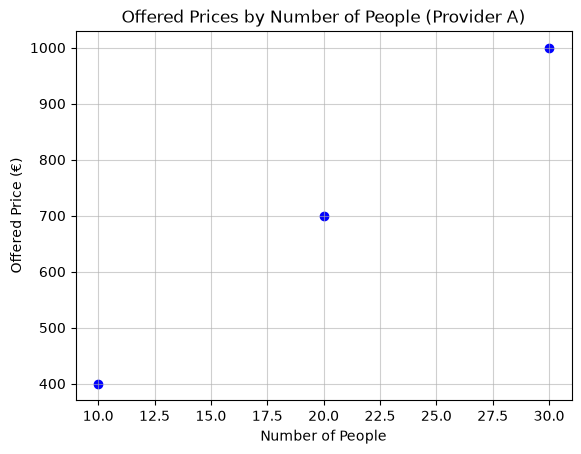

In [3]:
plt.scatter(num_people, offered_prices, color="blue")
plt.title("Offered Prices by Number of People (Provider A)")
plt.xlabel("Number of People")
plt.ylabel("Offered Price (€)")
plt.grid(True, alpha=0.6)
plt.show()

num_people wird umgeformt (reshaped), weil scikit-learn eine zweidimensionale Matrix für die Eingabedaten (Features) erwartet.

Der Grund: Ein Feature vs. Viele Features

In der Praxis hängt eine Vorhersage oft von mehreren Merkmalen (Features) ab – zum Beispiel der Personenanzahl und der Dauer eines Events. Deshalb verlangt model.fit(X, y) für X immer die Struktur (Anzahl der Datenpunkte, Anzahl der Merkmale).

Coef: [30.]
Intercept: 100.0


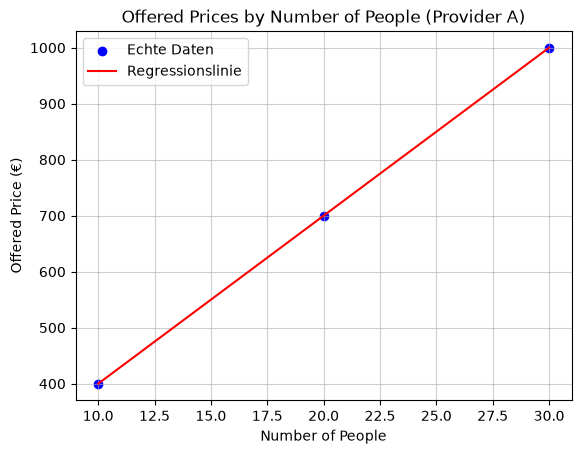

In [4]:
num_people_reshaped = [[n] for n in num_people] # reshape for sklearn, needed for fit. Double list structure
model = LinearRegression()
model.fit(num_people_reshaped, offered_prices)
print(f"Coef: {model.coef_}")
print(f"Intercept: {model.intercept_}")


# 1. Punkte zeichnen
plt.scatter(num_people, offered_prices, color="blue", label="Echte Daten")

# 2. Regressionslinie in dasselbe Diagramm zeichnen (ohne plt.show() dazwischen!)
plt.plot(num_people, model.predict(num_people_reshaped), color="red", label="Regressionslinie")

# Beschriftungen und Legende hinzufügen
plt.title("Offered Prices by Number of People (Provider A)")
plt.xlabel("Number of People")
plt.ylabel("Offered Price (€)")
plt.legend()
plt.grid(True, alpha=0.6)

# 3. Erst ganz am Ende das fertige Diagramm anzeigen
plt.show()


Alternative mit NumPy

Wenn du mit NumPy-Arrays arbeitest, kannst du statt der List Comprehension auch einfach .reshape(-1, 1) nutzen:

In [5]:
import numpy as np

np_people = np.array([10, 20, 30]).reshape(-1, 1)


Coef: [30.]
Intercept: 100.0


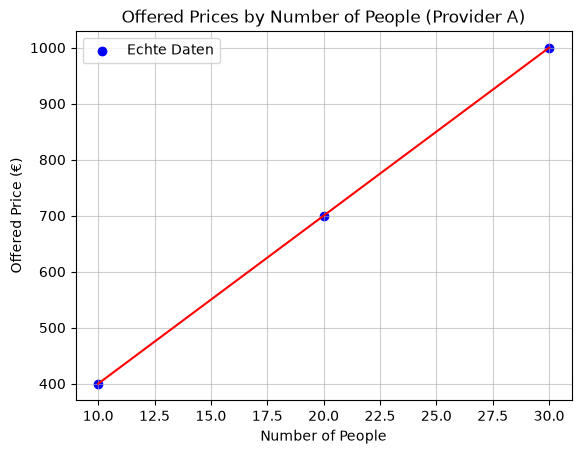

In [6]:
model.fit(np_people, offered_prices)
print(f"Coef: {model.coef_}")
print(f"Intercept: {model.intercept_}")

# 1. Punkte zeichnen
plt.scatter(num_people, offered_prices, color="blue", label="Echte Daten")

# 2. Regressionslinie in dasselbe Diagramm zeichnen (ohne plt.show() dazwischen!)
plt.plot(num_people, model.predict(np_people), color="red")
# Beschriftungen und Legende hinzufügen
plt.title("Offered Prices by Number of People (Provider A)")
plt.xlabel("Number of People")
plt.ylabel("Offered Price (€)")
plt.legend()
plt.grid(True, alpha=0.6)

# 3. Erst ganz am Ende das fertige Diagramm anzeigen
plt.show()



## Bewerten des Modells

Wir sehen uns an, wie gut das Modell die Testdaten vorhersagen kann, die
es noch nicht gesehen hat:


## Workshop: Pizza-Lieferzeit

In diesem Workshop werden wir ein einfaches Machine Learning Modell trainieren,
um die Lieferzeit einer Pizza basierend auf der Entfernung vom Restaurant
vorherzusagen.

In [7]:
pizza_distance = [
    1.0,
    1.5,
    2.0,
    2.5,
    3.0,
    3.5,
    4.0,
    4.5,
    5.0,
    5.5,
    6.0,
    6.5,
    7.0,
    7.5,
    8.0,
]

pizza_time = [15, 18, 20, 23, 25, 28, 30, 33, 35, 38, 40, 43, 45, 48, 50]

In [8]:
pizza_x = [[d] for d in pizza_distance] # reshape for model

In [9]:
# Aufteilen in Training und Test
pizza_x_train = pizza_x[:9]
pizza_y_train = pizza_time[:9]

pizza_x_test = pizza_x[9:]
pizza_y_test = pizza_time[9:]

In [34]:
model = LinearRegression()
model.fit(pizza_x_train, pizza_y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[5.]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,10.22
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.87]


In [11]:
print(f"Coefficient (slope): {model.coef_[0]:.2f}")
print(f"Intercept: {model.intercept_:.2f}")
print(f"Score: {model.score(pizza_x_test, pizza_y_test):.2f}")

Coefficient (slope): 5.00
Intercept: 10.22
Score: 1.00



Bewerten Sie das Modell mit dem Mean Absolute Error (MAE) und dem Mean Squared
Error (MSE) sowohl für die Trainings- als auch für die Testdaten.

In [12]:
train_predictions = model.predict(pizza_x_train)
test_predictions = model.predict(pizza_x_test)


In [13]:
def mean_absolute_error(y_true, y_pred):
    return sum(abs(a - b) for a, b in zip(y_true, y_pred)) / len(y_true)

def mean_squared_error(y_true, y_pred):
    return sum((a - b)**2 for a, b in zip(y_true, y_pred)) / len(y_true)

In [14]:
print(f"Training MAE: {mean_absolute_error(pizza_y_train, train_predictions):.2f}")
print(f"Training MSE: {mean_squared_error(pizza_y_train, train_predictions):.2f}")

Training MAE: 0.25
Training MSE: 0.06


In [15]:
print(f"Test MAE: {mean_absolute_error(pizza_y_test, test_predictions):.2f}")
print(f"Test MSE: {mean_squared_error(pizza_y_test, test_predictions):.2f}")

Test MAE: 0.25
Test MSE: 0.06


In [16]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_test = mean_absolute_error(pizza_y_test, test_predictions) 
mse_test = mean_squared_error(pizza_y_test, test_predictions)
mae_train = mean_absolute_error(pizza_y_train, train_predictions)
mse_train = mean_squared_error(pizza_y_train, train_predictions)    

In [17]:
print(f"MAE test: {mae_test:.2f}")
print(f"MSE test: {mse_test:.2f}")
print(f"MAE train: {mae_train:.2f}")
print(f"MSE train: {mse_train:.2f}")

MAE test: 0.25
MSE test: 0.06
MAE train: 0.25
MSE train: 0.06


### Weitere Beispiele Lineare Regression mit Diabetes-Daten
- Der Datensatz load_diabetes ist direkt in der Python-Bibliothek scikit-learn integriert und muss nicht separat aus dem Internet heruntergeladen werden.

In [18]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
import machine_learning_tutorial.regression_plots as rp


In [19]:
data = load_diabetes(as_frame=True) # Lade Diabetes-Daten as DataFrame
X = data.data # Features
y = data.target # Zielvariable

In [20]:
type(data)

sklearn.utils._bunch.Bunch

In [21]:
type(X), X.shape

(pandas.DataFrame, (442, 10))

In [22]:
X

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [23]:
y

0      151.0
1       75.0
2      141.0
3      206.0
4      135.0
       ...  
437    178.0
438    104.0
439    132.0
440    220.0
441     57.0
Name: target, Length: 442, dtype: float64

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train.shape

(309, 10)

In [25]:
model = LinearRegression()
model.fit(X_train, y_train)
print(f"Coef: {model.coef_}")
print(f"Intercept: {model.intercept_}")
print(f"Score: {model.score(X_test, y_test)}")

Coef: [  29.25401303 -261.7064691   546.29972304  388.39834056 -901.95966819
  506.76324136  121.15435079  288.03526689  659.26895081   41.37670105]
Intercept: 151.00821291456543
Score: 0.4772897164322618


In [26]:
test_pred = model.predict(X_test)

In [27]:
train_pred = model.predict(X_train)

In [28]:
mae = mean_absolute_error(y_test, test_pred)
r2 = r2_score(y_test, test_pred)
print(mae, r2)

41.919378456792735 0.4772897164322618


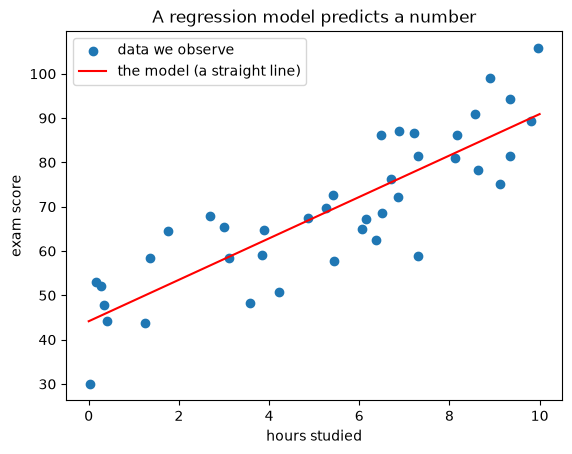

In [29]:
rp.show_line_fit()

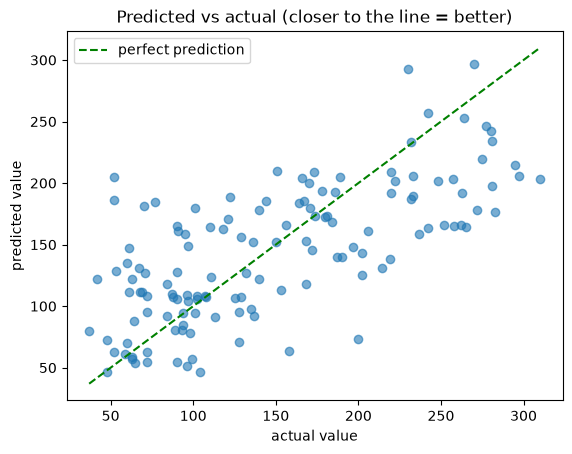

In [30]:
rp.plot_predicted_vs_actual(model, X_test, y_test)


## Ein einzelner Split kann Glück sein

- Ein einzelner Train/Test-Split kann zufällig besonders einfach (oder schwer) sein
- Wir möchten einen Score, der nicht von einem einzigen glücklichen Split abhängt

## Cross-Validation

- Teilen Sie die Daten auf mehrere Arten auf; trainieren und testen Sie auf jeder; mitteln Sie die Scores
- Jede Zeile kommt genau einmal in das Test-Set

In [31]:
from sklearn.model_selection import cross_val_score

In [32]:
cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2").mean()

np.float64(0.4823164359086422)

In [33]:
model.score(X, y)

0.5120874629222862